# TDA playground
Explorations inspired by the [scikit-tda tutorial](https://docs.scikit-tda.org/en/latest/notebooks/scikit-tda%20Tutorial.html#1.-Persistence-API), using Ripser, Persim, and TaDAsets.

**H0 counts connected components; H1 detects loops.** Each persistence point records a feature's birth and death as the maximum allowed edge length increases. Long lifetimes can suggest structure, but are not statistical significance tests.

Run cells in order. The setup installs missing packages in the selected kernel. Experiments use fixed random seeds.

In [1]:
import importlib.util
import subprocess
import sys
#packages = ["numpy", "matplotlib", "scipy", "ripser", "persim", "tadasets", "ipywidgets"]
##missing = [p for p in packages if importlib.util.find_spec(p) is None]
#if missing:
    #subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection
from scipy.spatial.distance import pdist, squareform
from ripser import ripser
from persim import plot_diagrams, bottleneck
import tadasets
import ipywidgets as widgets
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
colors = ["#167d9a", "#df7042", "#538b42"]
print("Kernel:", sys.executable)

Kernel: /Users/derickshi/anaconda3/envs/tda/bin/python


## 1. One loop, two loops, and a filled disk
Look for long H1 lifetimes in the circles. A finite sample of a disk may still have small holes. The two separated circles also produce an H0 class that lives until their components merge.

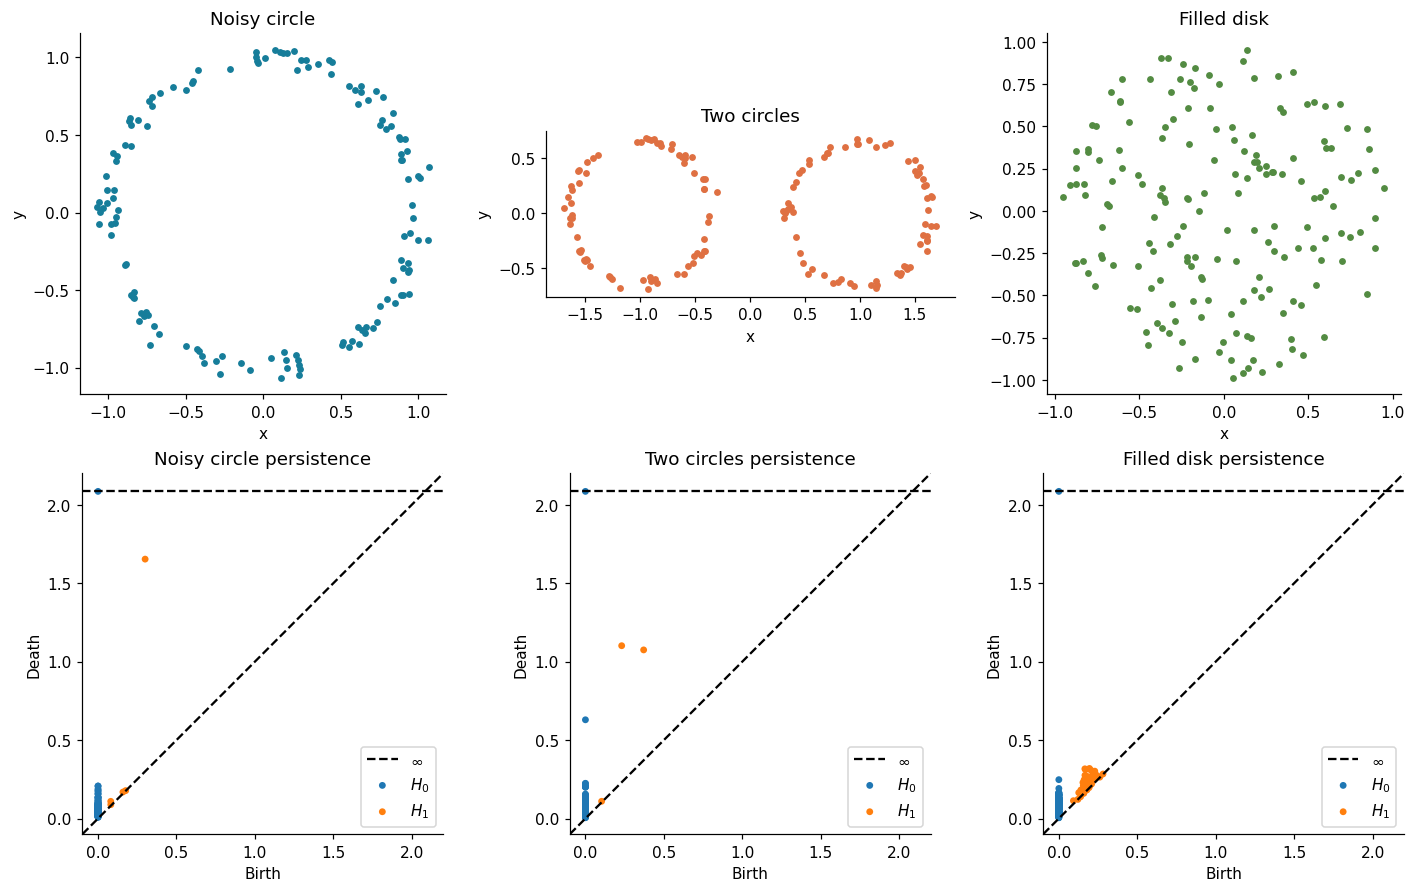

Noisy circle  : largest H1 lifetimes = [1.353 0.028 0.01  0.007 0.002]
Two circles   : largest H1 lifetimes = [0.87  0.704 0.006]
Filled disk   : largest H1 lifetimes = [0.151 0.141 0.124 0.109 0.102]


In [2]:
np.random.seed(42)
circle = tadasets.dsphere(n=140, d=1, noise=0.04)
rng = np.random.default_rng(42)
theta = rng.uniform(0, 2 * np.pi, 180)
radius = np.sqrt(rng.uniform(0, 1, 180))
disk = np.column_stack([radius * np.cos(theta), radius * np.sin(theta)])
two_circles = np.vstack([0.65 * circle[:70] + [-1, 0],
                         0.65 * circle[70:] + [1, 0]])
clouds = {"Noisy circle": circle, "Two circles": two_circles, "Filled disk": disk}
results = {name: ripser(points)["dgms"] for name, points in clouds.items()}
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
for col, (name, points) in enumerate(clouds.items()):
    axes[0, col].scatter(*points.T, s=12, color=colors[col])
    axes[0, col].set(title=name, xlabel="x", ylabel="y", aspect="equal")
    plot_diagrams(results[name], ax=axes[1, col], title=name + " persistence",
                  xy_range=[-0.1, 2.2, -0.1, 2.2])
plt.show()
for name, dgms in results.items():
    h1 = dgms[1]
    lifetimes = np.sort(h1[:, 1] - h1[:, 0])[::-1]
    print(f"{name:14s}: largest H1 lifetimes = {np.round(lifetimes[:5], 3)}")

## 2. Watch a loop appear and fill in
Epsilon is the **maximum edge length**, not a ball radius. Connect nearby pairs and fill each triangle whose three edges exist. Ripser computes the full complex; the drawing shows only vertices, edges, and triangles.

A feature is alive when birth <= epsilon < death. The counts in the middle panel come from persistence, since projected triangles can overlap and make the drawing misleading. H0 includes one class with infinite death: the final connected component.

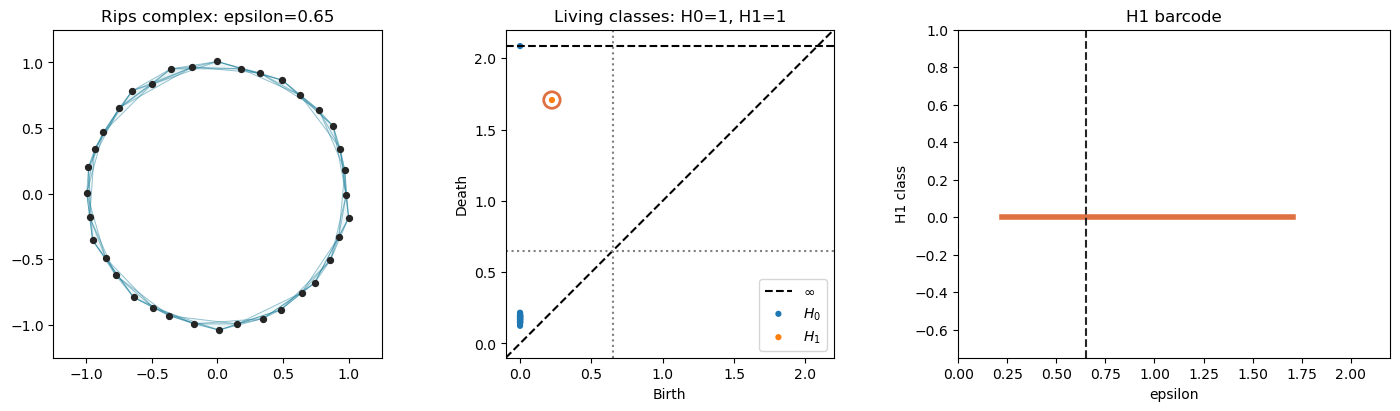

interactive(children=(FloatSlider(value=0.65, continuous_update=False, description='epsilon', max=2.1, step=0.…

In [3]:
angles = np.linspace(0, 2 * np.pi, 36, endpoint=False)
small = np.column_stack([np.cos(angles), np.sin(angles)])
small += np.random.default_rng(10).normal(0, 0.018, small.shape)
Dsmall = squareform(pdist(small))
small_dgms = ripser(Dsmall, distance_matrix=True)["dgms"]

def filtration_view(epsilon=0.65, triangles=True):
    adjacency = Dsmall <= epsilon
    edges = np.argwhere(np.triu(adjacency, 1))
    faces = [(i, j, k) for i, j in edges for k in range(j + 1, len(small))
             if adjacency[i, k] and adjacency[j, k]] if triangles else []
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    if faces:
        axes[0].add_collection(PolyCollection(small[np.asarray(faces)],
            facecolors=colors[0], edgecolors="none", alpha=0.025))
    if len(edges):
        axes[0].add_collection(LineCollection(small[edges],
            colors=colors[0], linewidths=0.7, alpha=0.45))
    axes[0].scatter(*small.T, s=18, color="#252525", zorder=3)
    axes[0].set(xlim=(-1.25, 1.25), ylim=(-1.25, 1.25), aspect="equal",
                title=f"Rips complex: epsilon={epsilon:.2f}")
    plot_diagrams(small_dgms, ax=axes[1], xy_range=[-0.1, 2.2, -0.1, 2.2])
    betti = []
    for dim, dgm in enumerate(small_dgms):
        alive = (dgm[:, 0] <= epsilon) & (epsilon < dgm[:, 1])
        betti.append(int(alive.sum()))
        active = dgm[alive & np.isfinite(dgm[:, 1])]
        axes[1].scatter(active[:, 0], active[:, 1], s=140,
                        facecolors="none", edgecolors=colors[dim], linewidths=2)
    axes[1].axvline(epsilon, color="gray", linestyle=":")
    axes[1].axhline(epsilon, color="gray", linestyle=":")
    axes[1].set_title(f"Living classes: H0={betti[0]}, H1={betti[1]}")
    for row, (birth, death) in enumerate(small_dgms[1]):
        axes[2].plot([birth, death], [row, row], color=colors[1], linewidth=4)
    axes[2].axvline(epsilon, color="#252525", linestyle="--")
    axes[2].set(xlim=(0, 2.2), xlabel="epsilon", ylabel="H1 class",
                title="H1 barcode", ylim=(-0.75, max(len(small_dgms[1]), 1)))
    plt.show()

filtration_view()
display(widgets.interactive(filtration_view,
    epsilon=widgets.FloatSlider(value=0.65, min=0, max=2.1, step=0.025,
                                description="epsilon", continuous_update=False),
    triangles=widgets.Checkbox(value=True, description="Fill triangles")))

## 3. How much noise can the loop tolerate?
Use identical base points and noise directions at every level, changing only the noise amplitude. Bottleneck distance compares the H1 diagrams to the clean baseline, allowing features to match to the diagonal.

This is one realization, not an average across seeds. Neither a monotonic response nor a universal noise cutoff is guaranteed.

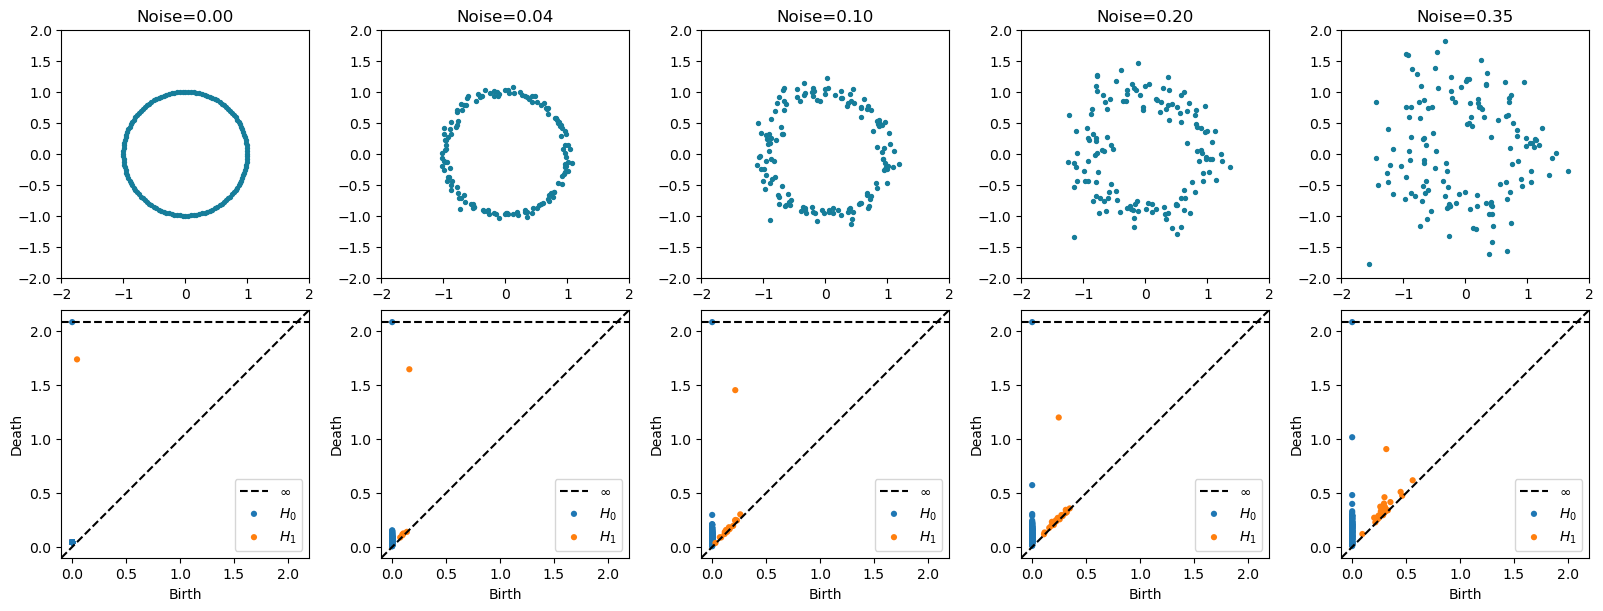

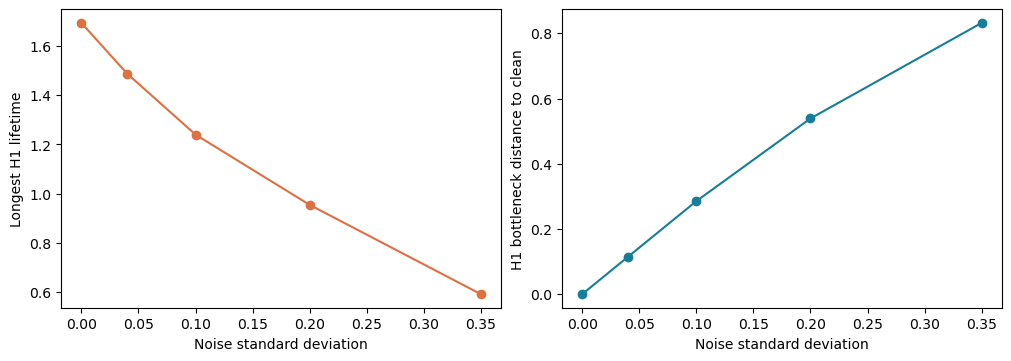

In [4]:
rng = np.random.default_rng(9)
angles = np.linspace(0, 2 * np.pi, 140, endpoint=False)
base = np.column_stack([np.cos(angles), np.sin(angles)])
directions = rng.normal(size=base.shape)
levels = [0.0, 0.04, 0.10, 0.20, 0.35]
samples = [base + sigma * directions for sigma in levels]
noise_dgms = [ripser(points)["dgms"] for points in samples]
fig, axes = plt.subplots(2, len(levels), figsize=(16, 6), constrained_layout=True)
for col, (sigma, points, dgms) in enumerate(zip(levels, samples, noise_dgms)):
    axes[0, col].scatter(*points.T, s=8, color=colors[0])
    axes[0, col].set(title=f"Noise={sigma:.2f}", aspect="equal",
                    xlim=(-2, 2), ylim=(-2, 2))
    plot_diagrams(dgms, ax=axes[1, col], xy_range=[-0.1, 2.2, -0.1, 2.2])
plt.show()
longest = [np.max(d[1][:, 1] - d[1][:, 0], initial=0) for d in noise_dgms]
distances_to_clean = [bottleneck(noise_dgms[0][1], d[1]) for d in noise_dgms]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].plot(levels, longest, "o-", color=colors[1])
axes[0].set(xlabel="Noise standard deviation", ylabel="Longest H1 lifetime")
axes[1].plot(levels, distances_to_clean, "o-", color=colors[0])
axes[1].set(xlabel="Noise standard deviation", ylabel="H1 bottleneck distance to clean")
plt.show()

## 4. Distance matrices and scale
Ripser can work directly with pairwise distances. The point-cloud and distance-matrix APIs should agree here. Scaling coordinates by 3 also scales birth and death values by 3: persistence uses the units of your metric.

Point-cloud and distance-matrix diagrams agree.


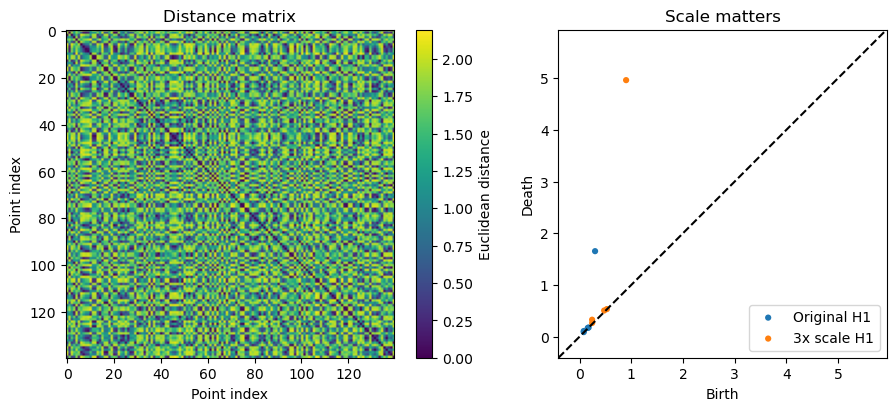

In [5]:
D = squareform(pdist(circle))
from_distances = ripser(D, distance_matrix=True)["dgms"]
for a, b in zip(results["Noisy circle"], from_distances):
    np.testing.assert_allclose(a, b, atol=1e-6)
print("Point-cloud and distance-matrix diagrams agree.")
scaled = ripser(3 * circle)["dgms"]
np.testing.assert_allclose(scaled[1] / 3, results["Noisy circle"][1], atol=1e-5)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
im = axes[0].imshow(D, cmap="viridis")
fig.colorbar(im, ax=axes[0], label="Euclidean distance")
axes[0].set(title="Distance matrix", xlabel="Point index", ylabel="Point index")
plot_diagrams([results["Noisy circle"][1], scaled[1]],
              labels=["Original H1", "3x scale H1"], ax=axes[1], title="Scale matters")
plt.show()

## 5. Your sandbox
Change shape, sample count, noise, or seed and rerun this cell. Larger samples increase computation time.

Try moving the two circles closer together in section 1, increasing the disk's sample count, or repeating the noise sweep with other seeds. Do small holes shrink as sampling becomes denser?

The slider needs widget support in your Jupyter frontend. Saved static plots remain visible without it.

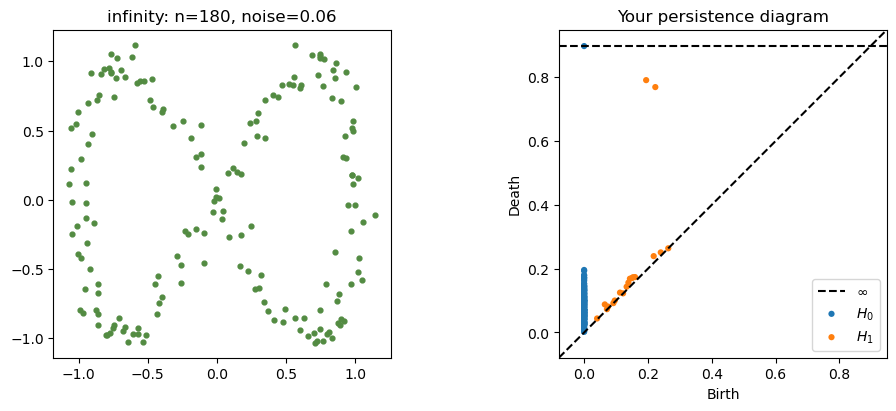

In [6]:
SHAPE = "infinity"  # "circle", "infinity", or "disk"
N = 180
NOISE = 0.06
SEED = 23

np.random.seed(SEED)
if SHAPE == "circle":
    X = tadasets.dsphere(n=N, d=1, noise=NOISE)
elif SHAPE == "infinity":
    X = tadasets.infty_sign(n=N, noise=NOISE)
elif SHAPE == "disk":
    rng = np.random.default_rng(SEED)
    theta = rng.uniform(0, 2 * np.pi, N)
    radius = np.sqrt(rng.uniform(0, 1, N))
    X = np.column_stack([radius * np.cos(theta), radius * np.sin(theta)])
    X += rng.normal(0, NOISE, X.shape)
else:
    raise ValueError("Choose circle, infinity, or disk.")
experiment = ripser(X, maxdim=1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].scatter(*X.T, s=12, color=colors[2])
axes[0].set(title=f"{SHAPE}: n={N}, noise={NOISE}", aspect="equal")
plot_diagrams(experiment["dgms"], ax=axes[1], title="Your persistence diagram")
plt.show()

## 6. Five dimensional sports profiles and H2

Each row below is a **fictional athlete profile** with five metrics: speed, stamina, agility, passing, and shooting. Three hidden training-style factors are sampled near the surface of a sphere, then mixed into all five scores. Thus the five observed columns form a curved **two dimensional shell embedded in five dimensions**. This is a deliberately constructed example with a known hollow center, not a claim about real athletes.

The raw metrics have different baselines and spreads. We standardize each column using the shell cloud's mean and standard deviation: `z = (score - mean) / standard deviation`. The filled control uses **the same** mean and standard deviation, so its distances stay comparable. Ripser then builds a Vietoris–Rips filtration from Euclidean distances in all five normalized dimensions. `maxdim=2` requests H0, H1, and H2; H2 measures two dimensional cycles surrounding a void. The fixed 64 point sample keeps this calculation small.


Five raw scores for the first three fictional profiles:
                speed  stamina  agility  passing shooting
                 72.1     70.4     84.6     62.9     78.2
                 68.0     65.7     83.9     63.8     81.1
                 75.2     66.8     84.8     55.3     77.3
Normalized shell column means: [-0. -0.  0. -0. -0.]
Normalized shell column stds:  [1. 1. 1. 1. 1.]
shell         : 1 finite H2 intervals
  longest (birth, death, lifetime): (1.464, 3.675, 2.211)
filled control: 3 finite H2 intervals
  longest (birth, death, lifetime): (1.54, 1.682, 0.142)
shell         : Betti-2 at epsilon=2.570 is 1
filled control: Betti-2 at epsilon=2.570 is 0


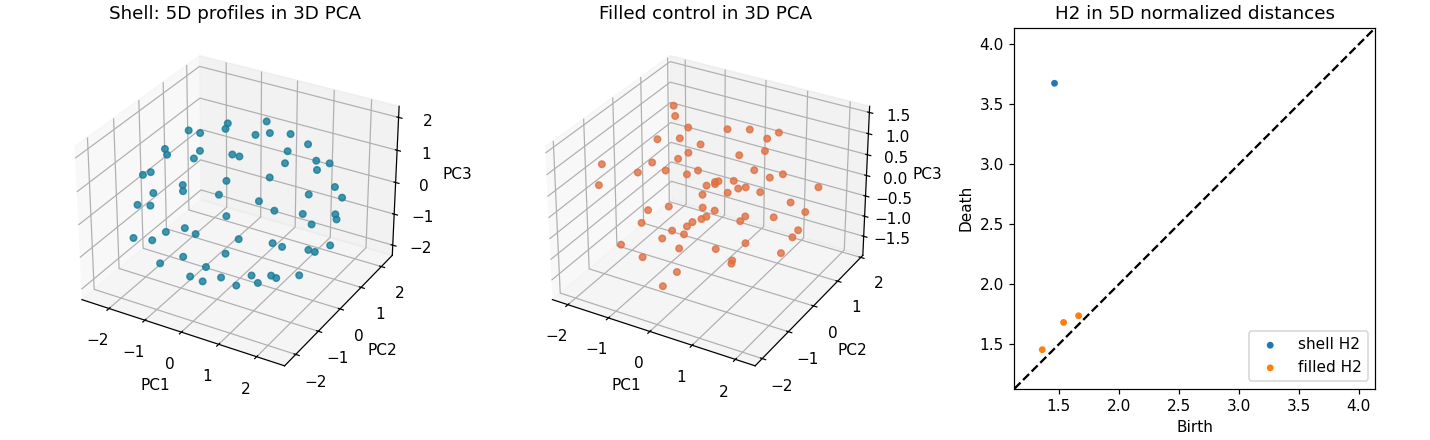

In [7]:
# Fixed size and seed: this section has no unbounded generation or search loop.
n_profiles = 64
sports_rng = np.random.default_rng(2026)
metric_names = ["speed", "stamina", "agility", "passing", "shooting"]

# Evenly spaced directions near a sphere surface in three hidden factors.
i = np.arange(n_profiles) + 0.5
z = 1 - 2 * i / n_profiles
phi = np.pi * (3 - np.sqrt(5)) * i
shell_factors = np.column_stack([
    np.sqrt(1 - z**2) * np.cos(phi),
    np.sqrt(1 - z**2) * np.sin(phi),
    z,
])
shell_factors += sports_rng.normal(0, 0.025, shell_factors.shape)

# Every metric depends on multiple factors; values are synthetic scores, not data.
mixing = np.array([
    [ 1.0,  0.2,  0.1],  # speed
    [ 0.1,  1.0,  0.2],  # stamina
    [ 0.2,  0.1,  1.0],  # agility
    [-0.8,  0.6,  0.1],  # passing
    [-0.4, -0.3,  0.85], # shooting
])
baseline = np.array([70, 65, 75, 60, 68])
score_spread = np.array([12, 15, 10, 18, 14])
shell_scores = baseline + (shell_factors @ mixing.T) * score_spread

# A solid three dimensional ball mapped into the same five score columns.
ball_directions = sports_rng.normal(size=(n_profiles, 3))
ball_directions /= np.linalg.norm(ball_directions, axis=1)[:, None]
ball_factors = ball_directions * sports_rng.uniform(0, 1, n_profiles)[:, None]**(1/3)
ball_scores = baseline + (ball_factors @ mixing.T) * score_spread

shell_mean = shell_scores.mean(axis=0)
shell_std = shell_scores.std(axis=0)
assert np.all(shell_std > 0)
shell_normalized = (shell_scores - shell_mean) / shell_std
ball_normalized = (ball_scores - shell_mean) / shell_std
np.testing.assert_allclose(shell_normalized.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(shell_normalized.std(axis=0), 1, atol=1e-12)

print("Five raw scores for the first three fictional profiles:")
print("             " + " ".join(f"{name:>8}" for name in metric_names))
for row in shell_scores[:3]:
    print("             " + " ".join(f"{value:8.1f}" for value in row))
print("Normalized shell column means:", np.round(shell_normalized.mean(axis=0), 3))
print("Normalized shell column stds: ", np.round(shell_normalized.std(axis=0), 3))

sports_shell_dgms = ripser(shell_normalized, maxdim=2)["dgms"]
sports_ball_dgms = ripser(ball_normalized, maxdim=2)["dgms"]

def finite_intervals(diagram):
    return sorted(((float(b), float(d), float(d-b)) for b, d in diagram
                   if np.isfinite(d)), key=lambda interval: interval[2], reverse=True)

shell_h2 = finite_intervals(sports_shell_dgms[2])
ball_h2 = finite_intervals(sports_ball_dgms[2])
for label, intervals in [("shell", shell_h2), ("filled control", ball_h2)]:
    print(f"{label:14}: {len(intervals)} finite H2 intervals")
    print("  longest (birth, death, lifetime):",
          tuple(round(x, 3) for x in intervals[0]) if intervals else "none")

# At this shared threshold, count the H2 classes alive in both filtrations.
probe = (shell_h2[0][0] + shell_h2[0][1]) / 2
for label, dgms in [("shell", sports_shell_dgms), ("filled control", sports_ball_dgms)]:
    betti_2 = sum(b <= probe < d for b, d in dgms[2])
    print(f"{label:14}: Betti-2 at epsilon={probe:.3f} is {betti_2}")

# A 3D PCA projection helps visualize the 5D clouds; Ripser used all five columns.
combined = np.vstack([shell_normalized, ball_normalized])
_, _, vt = np.linalg.svd(combined - combined.mean(axis=0), full_matrices=False)
projected_shell = (shell_normalized - combined.mean(axis=0)) @ vt[:3].T
projected_ball = (ball_normalized - combined.mean(axis=0)) @ vt[:3].T
fig = plt.figure(figsize=(13, 4), constrained_layout=True)
for index, (points, title, color) in enumerate([
    (projected_shell, "Shell: 5D profiles in 3D PCA", colors[0]),
    (projected_ball, "Filled control in 3D PCA", colors[1]),
]):
    ax = fig.add_subplot(1, 3, index + 1, projection="3d")
    ax.scatter(*points.T, s=18, alpha=0.8, color=color)
    ax.set(title=title, xlabel="PC1", ylabel="PC2", zlabel="PC3")
ax = fig.add_subplot(1, 3, 3)
plot_diagrams([sports_shell_dgms[2], sports_ball_dgms[2]],
              labels=["shell H2", "filled H2"], ax=ax,
              title="H2 in 5D normalized distances")
plt.show()


### What this synthetic experiment shows

With the fixed seed above, the shell has one H2 interval from about **1.46 to 3.68** (lifetime **2.21**) in normalized Euclidean distance. The filled control's longest H2 interval lasts only about **0.14**. At the shell interval's midpoint, the shell has Betti-2 = 1 and the filled control has Betti-2 = 0. That supports the narrow observation that **these generated profiles occupy a hollow shell, while the control fills its center**. Short H2 intervals in the control can arise from finite sampling.

The five metrics are correlated mixtures of three hidden factors. Standardization gives the named columns equal marginal variance, but it does not make them independent; the chosen mixing and Euclidean metric determine the shape. The 3D plots are PCA projections for intuition, while the persistence diagrams use all five normalized coordinates. A real sports dataset would need a defensible notion of distance, enough independent observations, and checks against null models before interpreting an H2 feature as a substantive pattern.
